### **BUSINESS UNDERSTANDING**

#### SDG 7: Affordable and Clean Energy 
#BUSINESS-UNDERSTANDING #SDG7 #Kenya #EnergyAccess

#### Why SDG 7
- Ensure access to affordable, reliable, sustainable and modern energy for all

#### Business objectives
1. Which countries lag on electricity access, and how has that changed since 2000?
2. Does a cleaner (more renewable) electricity mix go together with higher access?
3. What drives electricity access (income, urbanisation, energy mix)?

#### Success criteria
- Dashboard answers questions 1 and 2 clearly for a non-technical audience
- Regression predicts electricity access (% of population) with assumptions tested
  and reported with R² and MSE

#### Scope
Countries worldwide, 2000–2022, with a Kenya spotlight.

## **Data Understanding**



In [1]:
# #SETUP
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
from pathlib import Path
from functools import reduce

RAW = Path("../data/raw")
PROC = Path("../data/processed")
RAW.mkdir(parents=True, exist_ok=True)
PROC.mkdir(parents=True, exist_ok=True)
print("Setup done")

Setup done


In [2]:
# #DATA-COLLECTION #SOURCE:OurWorldInData
url = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"

cols = ["country", "year", "iso_code", "population", "gdp",
        "primary_energy_consumption", "energy_per_capita", "electricity_generation",
        "per_capita_electricity", "renewables_share_elec", "fossil_share_elec",
        "solar_share_elec", "wind_share_elec", "hydro_share_elec", "carbon_intensity_elec"]

owid = pd.read_csv(url, usecols=cols)
owid.to_csv(RAW / "owid_energy_raw.csv", index=False)   # #WHY keep an untouched copy

# #WHY rows without an iso_code are regions like "Africa" or "World", not countries
owid = owid[owid["iso_code"].notna() & owid["year"].between(2000, 2022)]
print(owid.shape)
owid.head()

(5040, 15)


,country,year,iso_code,population,gdp,carbon_intensity_elec,electricity_generation,energy_per_capita,fossil_share_elec,hydro_share_elec,per_capita_electricity,primary_energy_consumption,renewables_share_elec,solar_share_elec,wind_share_elec
126,Afghanistan,2000,AFG,20130334.0,1.128379e+10,250.00,0.48,262.680,35.417,64.583,23.845,5.288,64.583,0.0,0.0
127,Afghanistan,2001,AFG,20284303.0,1.102127e+10,217.39,0.69,179.892,27.536,72.464,34.016,3.649,72.464,0.0,0.0
128,Afghanistan,2002,AFG,21378123.0,1.880487e+10,169.01,0.71,155.695,21.127,78.873,33.212,3.328,78.873,0.0,0.0
129,Afghanistan,2003,AFG,22733053.0,2.107434e+10,241.76,0.91,174.558,30.769,69.231,40.030,3.968,69.231,0.0,0.0
130,Afghanistan,2004,AFG,23560656.0,2.233257e+10,227.85,0.79,157.758,29.114,70.886,33.530,3.717,70.886,0.0,0.0


In [ ]:
# #DATA-COLLECTION #SOURCE:WorldBankAPI #RETRY #CACHE
import time

indicators = {
    "EG.ELC.ACCS.ZS":    "access_electricity_pct",      # SDG 7.1.1
    "EG.FEC.RNEW.ZS":    "renewable_final_energy_pct",  # SDG 7.2.1
    "NY.GDP.PCAP.CD":    "gdp_per_capita_usd",
    "SP.URB.TOTL.IN.ZS": "urban_pop_pct",
}

def fetch_wb(code, name, retries=4):
    # #WHY if we already downloaded this indicator, reuse the saved file
    cache = RAW / f"wb_{code}.csv"
    if cache.exists():
        print(f"{name}: loaded from saved file")
        return pd.read_csv(cache)

    url = f"https://api.worldbank.org/v2/country/all/indicator/{code}"
    rows, page = [], 1

    while True:
        # #WHY small pages (1000 rows) are less likely to time out than one huge request
        params = {"format": "json", "per_page": 1000, "page": page, "date": "2000:2022"}

        for attempt in range(1, retries + 1):
            try:
                r = requests.get(url, params=params, timeout=(10, 120))
                r.raise_for_status()
                payload = r.json()
                if len(payload) < 2 or payload[1] is None:
                    raise ValueError(f"Empty response: {payload}")
                break
            except (requests.exceptions.RequestException, ValueError) as e:
                wait = 5 * attempt
                print(f"  {name} page {page}, attempt {attempt} failed ({type(e).__name__}). Retrying in {wait}s...")
                if attempt == retries:
                    raise
                time.sleep(wait)

        rows.extend(payload[1])
        print(f"  {name}: page {page} of {payload[0]['pages']} done")
        if page >= payload[0]["pages"]:
            break
        page += 1

    out = pd.DataFrame({
        "iso_code": [x["countryiso3code"] for x in rows],
        "year": [int(x["date"]) for x in rows],
        name: [x["value"] for x in rows],
    })
    out.to_csv(cache, index=False)
    return out

frames = [fetch_wb(code, name) for code, name in indicators.items()]
wb = reduce(lambda a, b: a.merge(b, on=["iso_code", "year"], how="outer"), frames)
wb = wb[wb["iso_code"] != ""]
wb.to_csv(RAW / "worldbank_sdg7_raw.csv", index=False)
print(wb.shape)
wb.head()

  access_electricity_pct: page 1 of 7 done
  access_electricity_pct: page 2 of 7 done
  access_electricity_pct: page 3 of 7 done
  access_electricity_pct: page 4 of 7 done
  access_electricity_pct: page 5 of 7 done
  access_electricity_pct: page 6 of 7 done
  access_electricity_pct: page 7 of 7 done
  renewable_final_energy_pct: page 1 of 7 done
  renewable_final_energy_pct: page 2 of 7 done
  renewable_final_energy_pct: page 3 of 7 done
  renewable_final_energy_pct: page 4 of 7 done
  renewable_final_energy_pct: page 5 of 7 done
  renewable_final_energy_pct: page 6 of 7 done
  renewable_final_energy_pct: page 7 of 7 done
  gdp_per_capita_usd: page 1 of 7 done
  gdp_per_capita_usd: page 2 of 7 done
  gdp_per_capita_usd: page 3 of 7 done
  gdp_per_capita_usd: page 4 of 7 done
  gdp_per_capita_usd: page 5 of 7 done
  gdp_per_capita_usd: page 6 of 7 done
  gdp_per_capita_usd: page 7 of 7 done
  urban_pop_pct: page 1 of 7 done
  urban_pop_pct: page 2 of 7 done
  urban_pop_pct: page 3 of 7 

,iso_code,year,access_electricity_pct,renewable_final_energy_pct,gdp_per_capita_usd,urban_pop_pct
14375,ABW,2000,91.7,0.2,20681.023027,65.354550
14376,ABW,2001,100.0,0.2,20740.132583,65.335114
14377,ABW,2002,100.0,0.2,21307.248251,65.282069
14378,ABW,2003,100.0,0.2,21949.485996,65.198292
14379,ABW,2004,100.0,0.2,23700.631990,65.088653


### Merge into one raw table

In [5]:
# #DATA-INTEGRATION
# #WHY left join: OWID is the country-and-year backbone, World Bank columns attach to it
df_raw = owid.merge(wb, on=["iso_code", "year"], how="left")
df_raw.to_csv(PROC / "sdg7_merged_raw.csv", index=False)
print(df_raw.shape)
df_raw.head()

(5040, 19)


,country,year,iso_code,population,gdp,carbon_intensity_elec,electricity_generation,energy_per_capita,fossil_share_elec,hydro_share_elec,per_capita_electricity,primary_energy_consumption,renewables_share_elec,solar_share_elec,wind_share_elec,access_electricity_pct,renewable_final_energy_pct,gdp_per_capita_usd,urban_pop_pct
0,Afghanistan,2000,AFG,20130334.0,1.128379e+10,250.00,0.48,262.680,35.417,64.583,23.845,5.288,64.583,0.0,0.0,4.4,45.0,174.930991,18.558200
1,Afghanistan,2001,AFG,20284303.0,1.102127e+10,217.39,0.69,179.892,27.536,72.464,34.016,3.649,72.464,0.0,0.0,9.3,45.6,138.706822,18.741238
2,Afghanistan,2002,AFG,21378123.0,1.880487e+10,169.01,0.71,155.695,21.127,78.873,33.212,3.328,78.873,0.0,0.0,14.1,37.8,178.954088,18.941248
3,Afghanistan,2003,AFG,22733053.0,2.107434e+10,241.76,0.91,174.558,30.769,69.231,40.030,3.968,69.231,0.0,0.0,19.0,36.7,198.871116,19.160035
4,Afghanistan,2004,AFG,23560656.0,2.233257e+10,227.85,0.79,157.758,29.114,70.886,33.530,3.717,70.886,0.0,0.0,23.8,44.2,221.763654,19.399359


### Dissect: what is in the table

In [6]:
# #DATA-UNDERSTANDING #STRUCTURE
print("Rows, columns:", df_raw.shape)
print("Countries:", df_raw["iso_code"].nunique())
print("Years:", df_raw["year"].min(), "to", df_raw["year"].max())
print()
df_raw.info()

Rows, columns: (5040, 19)
Countries: 220
Years: 2000 to 2022

<class 'pandas.DataFrame'>
RangeIndex: 5040 entries, 0 to 5039
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   country                     5040 non-null   str    
 1   year                        5040 non-null   int64  
 2   iso_code                    5040 non-null   str    
 3   population                  5005 non-null   float64
 4   gdp                         3790 non-null   float64
 5   carbon_intensity_elec       4866 non-null   float64
 6   electricity_generation      4889 non-null   float64
 7   energy_per_capita           4952 non-null   float64
 8   fossil_share_elec           4866 non-null   float64
 9   hydro_share_elec            4778 non-null   float64
 10  per_capita_electricity      4889 non-null   float64
 11  primary_energy_consumption  4987 non-null   float64
 12  renewables_share_elec       4866 non-nu

### Dissect: how mich is missing?

gdp                           24.8
renewable_final_energy_pct     9.2
gdp_per_capita_usd             8.5
wind_share_elec                7.4
access_electricity_pct         7.2
urban_pop_pct                  6.4
hydro_share_elec               5.2
solar_share_elec               3.8
carbon_intensity_elec          3.5
renewables_share_elec          3.5
fossil_share_elec              3.5
electricity_generation         3.0
per_capita_electricity         3.0
energy_per_capita              1.7
primary_energy_consumption     1.1
population                     0.7
iso_code                       0.0
country                        0.0
year                           0.0
dtype: float64


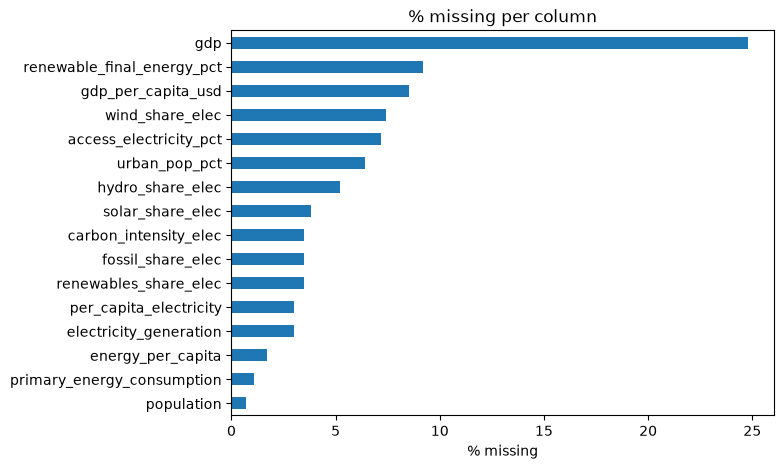

In [7]:
# #DATA-UNDERSTANDING #MISSING-VALUES
missing = (df_raw.isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing)

missing[missing > 0].sort_values().plot(kind="barh", figsize=(7, 5), title="% missing per column")
plt.xlabel("% missing")
plt.show()

 
 The chart shows which columns have gaps and which are close to empty. This decides the cleaning rules in Phase 3, so keep it open.

#### **Dissect: duplicates**

In [8]:
# #DATA-UNDERSTANDING #DUPLICATES
# #WHY each country should appear once per year, so more than 0 means a problem
print("Duplicate country-year rows:", df_raw.duplicated(subset=["iso_code", "year"]).sum())

Duplicate country-year rows: 0


#### dissect impossible values

In [9]:
# #DATA-UNDERSTANDING #VALIDITY
# #WHY percentages must sit between 0 and 100
pct_cols = ["access_electricity_pct", "renewable_final_energy_pct", "urban_pop_pct",
            "renewables_share_elec", "fossil_share_elec", "solar_share_elec",
            "wind_share_elec", "hydro_share_elec"]

for c in pct_cols:
    bad = ((df_raw[c] < 0) | (df_raw[c] > 100)).sum()
    print(f"{c}: {bad} impossible values")

# #WHY these can never be negative
nonneg = ["population", "gdp_per_capita_usd", "per_capita_electricity", "energy_per_capita"]
print()
print((df_raw[nonneg] < 0).sum())

access_electricity_pct: 0 impossible values
renewable_final_energy_pct: 0 impossible values
urban_pop_pct: 0 impossible values
renewables_share_elec: 0 impossible values
fossil_share_elec: 0 impossible values
solar_share_elec: 0 impossible values
wind_share_elec: 0 impossible values
hydro_share_elec: 0 impossible values

population                0
gdp_per_capita_usd        0
per_capita_electricity    0
energy_per_capita         0
dtype: int64


#### Descriptive stats

In [10]:
# #DATA-UNDERSTANDING #DESCRIPTIVE-STATS
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
year,5040.0,2.011030e+03,6.630000e+00,2.000000e+03,2.005000e+03,2.011000e+03,2.017000e+03,2.022000e+03
population,5005.0,3.264637e+07,1.299453e+08,1.776000e+03,7.093870e+05,5.728196e+06,2.137812e+07,1.426437e+09
gdp,3790.0,5.697030e+11,1.921936e+12,3.128536e+08,2.366483e+10,7.727651e+10,3.515815e+11,2.696602e+13
carbon_intensity_elec,4866.0,4.775900e+02,2.482600e+02,0.000000e+00,2.859100e+02,5.332900e+02,6.538500e+02,1.306720e+03
electricity_generation,4889.0,1.025700e+02,4.742100e+02,0.000000e+00,6.800000e-01,6.970000e+00,4.357000e+01,8.848710e+03
energy_per_capita,4952.0,2.697166e+04,4.298277e+04,0.000000e+00,3.077780e+03,1.291344e+04,3.509806e+04,6.518366e+05
fossil_share_elec,4866.0,6.568000e+01,3.372000e+01,0.000000e+00,3.941000e+01,7.524000e+01,9.836000e+01,1.000000e+02
hydro_share_elec,4778.0,2.595000e+01,3.157000e+01,0.000000e+00,0.000000e+00,1.021000e+01,4.716000e+01,1.000000e+02
per_capita_electricity,4889.0,3.794880e+03,5.197700e+03,0.000000e+00,4.947200e+02,2.130830e+03,5.236300e+03,5.604873e+04
primary_energy_consumption,4987.0,6.517400e+02,2.881120e+03,0.000000e+00,5.010000e+00,3.876000e+01,2.947900e+02,4.451649e+04


#### Look at the target: electricity access

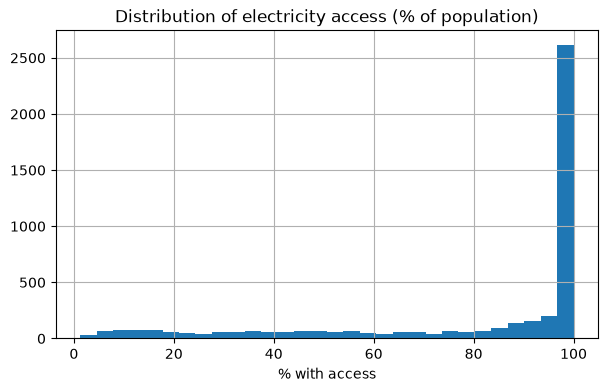

count    4677.0
mean       80.5
std        29.3
min         1.3
25%        66.1
50%        98.8
75%       100.0
max       100.0
Name: access_electricity_pct, dtype: float64


In [12]:
# #DATA-UNDERSTANDING #TARGET:access_electricity_pct
df_raw["access_electricity_pct"].hist(bins=30, figsize=(7, 4))
plt.title("Distribution of electricity access (% of population)")
plt.xlabel("% with access")
plt.show()

print(df_raw["access_electricity_pct"].describe().round(1))

# this shape matters later when we test the regression assumptions


#### Answer the business questions so far

In [13]:
# #DATA-UNDERSTANDING #SDG7.1.1
latest = df_raw[df_raw["year"] == 2022]
print("10 lowest-access countries, 2022")
print(latest.nsmallest(10, "access_electricity_pct")[["country", "access_electricity_pct"]])

print("\nKenya, last 10 years")
df_raw[df_raw["country"] == "Kenya"][["year", "access_electricity_pct", "renewables_share_elec"]].tail(10)

10 lowest-access countries, 2022
                           country  access_electricity_pct
4257                   South Sudan                     8.4
735                        Burundi                    10.3
896                           Chad                    11.7
2733                        Malawi                    14.0
873       Central African Republic                    15.7
3556              Papua New Guinea                    19.0
712                   Burkina Faso                    19.5
3303                         Niger                    19.5
1218  Democratic Republic of Congo                    21.5
4085                  Sierra Leone                    29.4

Kenya, last 10 years


,year,access_electricity_pct,renewables_share_elec
2402,2013,40.1,78.342
2403,2014,36.0,76.413
2404,2015,41.6,89.806
2405,2016,53.1,89.256
2406,2017,55.8,80.886
2407,2018,61.2,86.283
2408,2019,69.7,88.668
2409,2020,71.5,93.579
2410,2021,76.5,89.822
2411,2022,76.0,87.809


### **Data Preparation (cleaning)**

In [14]:
# working on a copy 

# DATA-PREPARATION #STEP1
# WHY df_raw stays untouched so we can always compare before and after
df = df_raw.copy()
df = df.sort_values(["iso_code", "year"]).reset_index(drop=True)
print("Starting rows:", len(df))


Starting rows: 5040


In [15]:
# Drop rows where the target is missing

# DATA-PREPARATION #STEP2 #TARGET
# WHY we cannot learn from or chart a country-year with no access figure,
#      and we should never invent the thing we are trying to explain
before = len(df)
df = df.dropna(subset=["access_electricity_pct"])
print(f"Dropped {before - len(df)} rows. Remaining: {len(df)}")


Dropped 363 rows. Remaining: 4677


In [16]:
# Drop columns that are redundant or mostly empty

# DATA-PREPARATION #STEP3 #COLUMNS
# Rule 1: more than 40% missing means too little left to trust
too_sparse = missing[missing > 40].index.tolist()

# Rule 2: total columns just reflect country size. We keep per-capita versions
#         and the World Bank GDP per capita instead.
redundant = ["gdp", "primary_energy_consumption", "electricity_generation"]

to_drop = [c for c in (too_sparse + redundant) if c in df.columns]
df = df.drop(columns=to_drop)
print("Dropped columns:", to_drop)
print("Columns left:", df.shape[1])

Dropped columns: ['gdp', 'primary_energy_consumption', 'electricity_generation']
Columns left: 16


In [17]:
# fill the gaps in the predictors

# DATA-PREPARATION #STEP4 #IMPUTATION
# WHY fill within each country over time (a gap in 2011 is best guessed from
#      Kenya's 2010 and 2012), not with one global average that ignores the country.
# WHY limit=3 stops us from guessing across long stretches of nothing.
# WHY we do not touch the target column.
fill_cols = [c for c in df.select_dtypes("number").columns
             if c not in ["year", "access_electricity_pct"]]

print("Missing BEFORE:")
print(df[fill_cols].isna().sum())

df[fill_cols] = df.groupby("iso_code")[fill_cols].transform(
    lambda s: s.interpolate(limit=3, limit_direction="both")
)

print("\nMissing AFTER:")
print(df[fill_cols].isna().sum())

Missing BEFORE:
population                      0
carbon_intensity_elec          92
energy_per_capita              53
fossil_share_elec              92
hydro_share_elec              161
per_capita_electricity         92
renewables_share_elec          92
solar_share_elec               95
wind_share_elec               260
renewable_final_energy_pct    141
gdp_per_capita_usd             97
urban_pop_pct                   0
dtype: int64

Missing AFTER:
population                      0
carbon_intensity_elec          92
energy_per_capita              49
fossil_share_elec              92
hydro_share_elec              161
per_capita_electricity         92
renewables_share_elec          92
solar_share_elec               92
wind_share_elec               217
renewable_final_energy_pct      0
gdp_per_capita_usd             76
urban_pop_pct                   0
dtype: int64


In [18]:
# Dropping rows that are still incomplete

# DATA-PREPARATION #STEP5 #ROWS
# WHY the gaps left are too long to fill honestly, and regression cannot take blanks
before = len(df)
df = df.dropna(subset=fill_cols)
print(f"Dropped {before - len(df)} rows. Remaining: {len(df)}")
print("Countries still in the data:", df["iso_code"].nunique())

Dropped 339 rows. Remaining: 4338
Countries still in the data: 194


solar_share_elec              874
wind_share_elec               871
population                    493
gdp_per_capita_usd            390
energy_per_capita             243
per_capita_electricity        213
carbon_intensity_elec          23
fossil_share_elec               0
renewables_share_elec           0
hydro_share_elec                0
renewable_final_energy_pct      0
urban_pop_pct                   0
dtype: int64


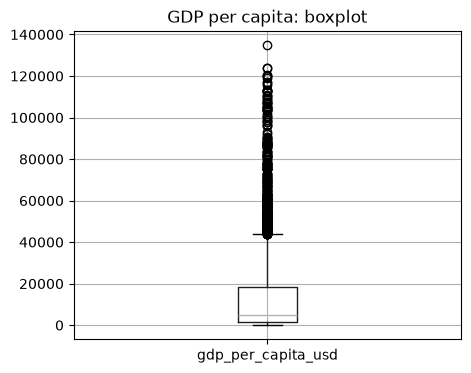

In [19]:
# checking for outliers (looking and not deleting)

 #DATA-PREPARATION #STEP6 #OUTLIERS
Q1 = df[fill_cols].quantile(0.25)
Q3 = df[fill_cols].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[fill_cols] < (Q1 - 1.5 * IQR)) | (df[fill_cols] > (Q3 + 1.5 * IQR))).sum()
print(outliers.sort_values(ascending=False))

df.boxplot(column="gdp_per_capita_usd", figsize=(5, 4))
plt.title("GDP per capita: boxplot")
plt.show()

In [20]:
# create new useful columns

# DATA-PREPARATION #STEP7 #FEATURE-ENGINEERING
# WHY GDP is heavily skewed, and log makes it behave better in a linear model
df["gdp_per_capita_log"] = np.log(df["gdp_per_capita_usd"])

# WHY the "gap" is easier to talk about in a dashboard: how many people are left without power
df["electricity_gap_pct"] = 100 - df["access_electricity_pct"]

df[["country", "year", "gdp_per_capita_usd", "gdp_per_capita_log", "electricity_gap_pct"]].head()

,country,year,gdp_per_capita_usd,gdp_per_capita_log,electricity_gap_pct
0,Aruba,2000,20681.023027,9.936972,8.3
1,Aruba,2001,20740.132583,9.939826,0.0
2,Aruba,2002,21307.248251,9.966803,0.0
3,Aruba,2003,21949.485996,9.996499,0.0
4,Aruba,2004,23700.631990,10.073257,0.0


In [21]:
# Final health check

# DATA-PREPARATION #STEP8 #VALIDATION
print("Shape:", df.shape)
print("Missing values left:", df.isna().sum().sum())
print("Duplicates:", df.duplicated(subset=["iso_code", "year"]).sum())
print("Kenya rows kept:", (df["country"] == "Kenya").sum())
print(f"Rows kept: {len(df)} of {len(df_raw)} ({len(df)/len(df_raw):.0%})")
df.describe().T.round(2)


Shape: (4338, 18)
Missing values left: 0
Duplicates: 0
Kenya rows kept: 23
Rows kept: 4338 of 5040 (86%)


,count,mean,std,min,25%,50%,75%,max
year,4338.0,2011.14,6.600000e+00,2000.00,2005.00,2011.00,2017.00,2.022000e+03
population,4338.0,37015029.19,1.390318e+08,10032.00,1395492.75,7205717.50,25234220.75,1.426437e+09
carbon_intensity_elec,4338.0,459.63,2.484800e+02,0.00,257.02,505.36,649.15,1.306720e+03
energy_per_capita,4338.0,25672.52,4.100049e+04,101.88,3044.52,12180.62,33996.09,6.518366e+05
fossil_share_elec,4338.0,63.61,3.420000e+01,0.00,36.47,71.97,96.57,1.000000e+02
hydro_share_elec,4338.0,27.18,3.217000e+01,0.00,0.04,11.34,49.13,1.000000e+02
per_capita_electricity,4338.0,3716.34,5.356930e+03,4.81,450.10,1922.86,5125.78,5.604873e+04
renewables_share_elec,4338.0,32.46,3.332000e+01,0.00,2.69,19.46,57.52,1.000000e+02
solar_share_elec,4338.0,0.86,2.600000e+00,0.00,0.00,0.00,0.24,3.788000e+01
wind_share_elec,4338.0,1.68,4.890000e+00,0.00,0.00,0.00,0.56,5.714000e+01


In [22]:
# save the clean data for Power BI to use

#DATA-PREPARATION #STEP9 #EXPORT
df.to_csv(PROC / "sdg7_clean.csv", index=False)
print("Saved to", PROC / "sdg7_clean.csv")

Saved to ..\data\processed\sdg7_clean.csv
